# Xây dựng EfficientNet-B0 (Google Research - Tan & Le, 2019) cho Oxford-IIIT Pet từ đầu (Data-Centric Foreground Edition)

**Yêu cầu xây dựng model:**
- Input: 224x224x3
- Classes: 37 giống loài (12 giống mèo, 25 giống chó) thuộc 2 loài động vật Chó và Mèo
- Framework: PyTorch
- Pretrained: Không sử dụng (From Scratch)

> **Lưu ý Data-Centric:** Notebook này được trang bị tiền xử lý Foreground Extraction (cắt chặt BBox vật thể từ Trimap) và Background Neutralization (khử nền xám trung tính $) để bảo đảm đối sánh công bằng 100% với PetNet-Hybrid V3.


In [1]:
# [Môi trường Kaggle / Colab] Tự động tải mã nguồn từ GitHub và chuyển vào đúng thư mục làm việc
import os

if os.path.exists("/kaggle"):
    %cd /kaggle/working
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    %cd /kaggle/working/ml-semester-cat-dog-classifier/notebooks/10_efficientnet
elif os.path.exists("/content"):
    %cd /content
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    %cd /content/ml-semester-cat-dog-classifier/notebooks/10_efficientnet


/kaggle/working
Cloning into 'ml-semester-cat-dog-classifier'...
remote: Enumerating objects: 177, done.
remote: Counting objects: 100% (177/177), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 177 (delta 87), reused 165 (delta 75), pack-reused 0 (from 0)
Receiving objects: 100% (177/177), 143.79 KiB | 3.27 MiB/s, done.
Resolving deltas: 100% (87/87), done.
/kaggle/working/ml-semester-cat-dog-classifier/notebooks/10_efficientnet


## Bước 1: Input các thư viện

In [2]:
import os
import sys
import json
import random
import argparse
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix

# Thiết lập Random Seed chuẩn xác và Deterministic cho Card T4 GPU
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Tự động tìm thư mục gốc chứa package src (tương thích cả clone mới, Colab, Jupyter)
from pathlib import Path
current_path = Path.cwd()
project_root = None
for parent in [current_path, current_path.parent, current_path.parent.parent]:
    if (parent / "src").is_dir():
        project_root = parent
        break

if project_root is not None:
    for p in [str(project_root), str(project_root / "src")]:
        if p not in sys.path:
            sys.path.insert(0, p)

# Nạp modules: import chuẩn từ package src (IDE linter nhận diện ngay không cần file cấu hình)
try:
    from src.dataset import OxfordPetDataset, get_transforms, CLAHETransform
except ImportError:
    from dataset import OxfordPetDataset, get_transforms, CLAHETransform

device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
if torch.cuda.is_available():
    print(f"Thiết bị đang sử dụng: {torch.cuda.get_device_name(0)} (CUDA T4) | Seed: {SEED}")
else:
    print(f"Thiết bị đang sử dụng: {device} | Seed: {SEED}")

Thiết bị đang sử dụng: Tesla T4 (CUDA T4) | Seed: 42


## Bước 2: Argparse & Thiết lập siêu tham số

In [3]:
def parse_args():
    parser = argparse.ArgumentParser(description="EfficientNet-B0 (Tan & Le, 2019) (High Accuracy on T4)")
    # Cấu hình tối ưu độ chính xác trên GPU 16GB VRAM (Tesla T4)
    # Tự động định vị thư mục dataset trên mọi môi trường (Local / Colab)
    default_data_dir = "../../dataset/oxford-iiit-pet"
    if project_root and (project_root / "dataset" / "oxford-iiit-pet").exists():
        default_data_dir = str(project_root / "dataset" / "oxford-iiit-pet")
    elif project_root and (project_root / "dataset").exists():
        default_data_dir = str(project_root / "dataset" / "oxford-iiit-pet")
    parser.add_argument("--data_dir", type=str, default=default_data_dir)
    parser.add_argument("--task", type=str, default="breed", choices=["breed", "binary"])
    parser.add_argument("--img_size", type=int, default=224, help="Kích thước ảnh chuẩn 224x224")
    parser.add_argument("--batch_size", type=int, default=64, help="Batch size 64 tối ưu ước lượng gradient đa lớp trên T4")
    parser.add_argument("--epochs", type=int, default=100, help="Số epochs huấn luyện 100")
    parser.add_argument("--lr", type=float, default=5e-4, help="Learning rate tinh chỉnh 0.0005 cho AdamW")
    parser.add_argument("--weight_decay", type=float, default=1e-2, help="Decoupled weight decay 0.01 chống overfitting")
    parser.add_argument("--label_smoothing", type=float, default=0.1, help="Label smoothing 0.1 tăng khả năng tổng quát hóa")
    parser.add_argument("--checkpoint_dir", type=str, default="./checkpoints/foreground")
    parser.add_argument("--plots_dir", type=str, default="./plots/foreground")
    parser.add_argument("--crop_foreground", type=bool, default=True, help="Cắt chặt Bounding Box vùng thú cưng")
    parser.add_argument("--remove_background", type=bool, default=True, help="Khử nền xám trung tính")
    try:
        args, _ = parser.parse_known_args()
    except:
        args = parser.parse_args([])
    return args

args = parse_args()

print(f"Chế độ Data-Centric: Crop Foreground = {args.crop_foreground} | Neutral Gray BG = {args.remove_background}")


Chế độ Data-Centric: Crop Foreground = True | Neutral Gray BG = True


## Bước 3: Load Data & Data-Centric Foreground Extraction

Để đảm bảo tính đối sánh công bằng chính xác với kiến trúc PetNet-Hybrid V3, mô hình này được áp dụng cùng cơ chế **Data-Centric AI**:
1. **Trimap BBox Crop:** Tự động cắt chặt theo hộp bao của toàn bộ cơ thể và khuôn mặt thú cưng, loại bỏ các viền cảnh nền trống.
2. **Background Neutralization:** Khử toàn bộ các pixel cảnh nền (sofa, bãi cỏ, sàn nhà) thành màu xám trung tính $ nhằm triệt tiêu gradient nhiễu ngoại cảnh.
3. **Augmentation:** Duy trì đầy đủ CLAHE LAB và Part Crop Augmentation để trích xuất hoa văn lông và tai/mắt.


>> [DATASET] Chưa có ảnh tại ../../dataset/oxford-iiit-pet. Đang tự động tải Oxford-IIIT Pet từ torchvision...


100%|██████████| 792M/792M [00:21<00:00, 36.4MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.6MB/s]


Tổng số mẫu Train: 3,680 | Test: 3,669 | Số lớp: 37
Batch Size: 64 | Kích thước ảnh: 224x224 px


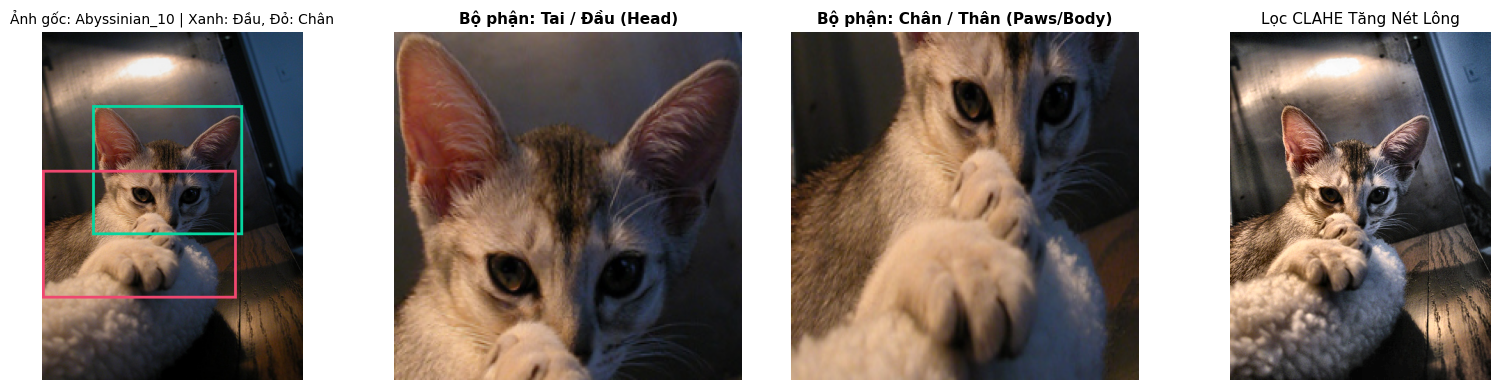

In [4]:
from PIL import Image
import torchvision.transforms.functional as TF

class OxfordPetForegroundDataset(OxfordPetDataset):
    """
    OxfordPetForegroundDataset:
    Tự động khai thác file Trimap Segmentation để:
    1. Xác định Bounding Box chặt bao quanh thú cưng (khuôn mặt, tai, thân, chân)
    2. Cắt bỏ (crop) các vùng cảnh nền dư thừa bên ngoài với padding an toàn (4%)
    3. Xóa các pixel nền (background pixels = 2) thành màu xám trung tính (128, 128, 128)
       nhằm loại bỏ 100% rác môi trường (ghế sofa, người bế, bãi cỏ, thảm),
       giúp mô hình tập trung tối đa vào hình thái và hoa văn đặc trưng của giống.
    """
    def __init__(self, *args, remove_background=True, crop_foreground=True, bg_color=(128, 128, 128), **kwargs):
        super().__init__(*args, **kwargs)
        self.remove_background = remove_background
        self.crop_foreground = crop_foreground
        self.bg_color = bg_color
        self.trimaps_dir = os.path.join(self.root_dir, "annotations", "trimaps")

    def __getitem__(self, idx):
        img_path, target, class_id, spec_id, img_name = self.samples[idx]
        with Image.open(img_path) as img:
            img = img.convert("RGB")

        trimap_path = os.path.join(self.trimaps_dir, f"{img_name}.png")
        if os.path.exists(trimap_path) and (self.remove_background or self.crop_foreground):
            try:
                trimap = Image.open(trimap_path)
                if trimap.size != img.size:
                    trimap = trimap.resize(img.size, Image.NEAREST)

                t_arr = np.array(trimap)
                img_arr = np.array(img)

                fg_mask = (t_arr == 1) | (t_arr == 3)

                if self.crop_foreground:
                    y_indices, x_indices = np.where(fg_mask)
                    if len(y_indices) > 0 and len(x_indices) > 0:
                        h, w = t_arr.shape
                        pad_y = int(0.04 * h)
                        pad_x = int(0.04 * w)
                        ymin = max(0, y_indices.min() - pad_y)
                        ymax = min(h, y_indices.max() + pad_y)
                        xmin = max(0, x_indices.min() - pad_x)
                        xmax = min(w, x_indices.max() + pad_x)

                        img_arr = img_arr[ymin:ymax, xmin:xmax]
                        t_arr = t_arr[ymin:ymax, xmin:xmax]

                if self.remove_background:
                    bg_mask = (t_arr == 2)
                    img_arr[bg_mask] = self.bg_color

                img = Image.fromarray(img_arr)
            except Exception:
                pass

        if self.transform is not None:
            tensor = self.transform(img)
        else:
            tensor = TF.to_tensor(img)

        return tensor, target, {
            "image_name": img_name,
            "breed_name": self.class_names[class_id],
            "species": "Cat" if spec_id == 0 else "Dog",
            "class_id": class_id,
            "species_id": spec_id
        }


# Data Augmentation nâng cao: Extreme Part Crop (8% - 40% diện tích) + CLAHE LAB
train_transform = get_transforms(img_size=args.img_size, is_train=True, use_part_aug=True, use_clahe=True)
test_transform = get_transforms(img_size=args.img_size, is_train=False)

trainset = OxfordPetForegroundDataset(root_dir=args.data_dir, split="trainval", task=args.task, transform=train_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background)
trainloader = DataLoader(trainset, batch_size=args.batch_size, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())

testset = OxfordPetForegroundDataset(root_dir=args.data_dir, split="test", task=args.task, transform=test_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background)
testloader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

classes = trainset.class_names if args.task == "breed" else ["Cat", "Dog"]
num_classes = len(classes)
print(f"Tổng số mẫu Train: {len(trainset):,} | Test: {len(testset):,} | Số lớp: {num_classes}")
print(f"Batch Size: {args.batch_size} | Kích thước ảnh: {args.img_size}x{args.img_size} px")

# Trích xuất và trực quan hóa bộ phận chính xác kết hợp Trimap (tách nền) + XML Ground Truth
import numpy as np
import xml.etree.ElementTree as ET
from PIL import ImageDraw

def extract_parts_trimap_xml(img_path, annotations_dir, target_size=(224, 224)):
    img = Image.open(img_path).convert("RGB")
    w, h = img.size
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    
    xml_path = os.path.join(annotations_dir, "xmls", f"{base_name}.xml")
    trimap_path = os.path.join(annotations_dir, "trimaps", f"{base_name}.png")
    
    # 1. Trích xuất Head BBox từ XML nếu có
    head_box = None
    if os.path.exists(xml_path):
        try:
            tree = ET.parse(xml_path)
            bndbox = tree.getroot().find("object").find("bndbox")
            xmin = max(0, int(bndbox.find("xmin").text))
            ymin = max(0, int(bndbox.find("ymin").text))
            xmax = min(w, int(bndbox.find("xmax").text))
            ymax = min(h, int(bndbox.find("ymax").text))
            head_box = (xmin, ymin, xmax, ymax)
        except Exception:
            pass

    # 2. Trích xuất Mask cơ thể chó/mèo từ Trimap (1 = pet body, 3 = contour) để loại bỏ 100% nền nhà
    body_box = None
    if os.path.exists(trimap_path):
        try:
            tri_arr = np.array(Image.open(trimap_path))
            pet_mask = (tri_arr == 1) | (tri_arr == 3)
            
            if head_box is not None:
                # Lọc các pixel thuộc thân thể nằm phía dưới tâm đầu (loại bỏ hoàn toàn nền nhà)
                head_mid_y = int((head_box[1] + head_box[3]) / 2)
                lower_body_mask = pet_mask.copy()
                lower_body_mask[:head_mid_y, :] = False
                
                indices = np.argwhere(lower_body_mask)
                if len(indices) > 50:
                    b_ymin, b_xmin = indices.min(axis=0)
                    b_ymax, b_xmax = indices.max(axis=0)
                    body_box = (int(b_xmin), int(b_ymin), int(b_xmax), int(b_ymax))
            
            if body_box is None:
                indices = np.argwhere(pet_mask)
                if len(indices) > 50:
                    ymin_f, xmin_f = indices.min(axis=0)
                    ymax_f, xmax_f = indices.max(axis=0)
                    body_box = (int(xmin_f), int(ymin_f + 0.4 * (ymax_f - ymin_f)), int(xmax_f), int(ymax_f))
                    if head_box is None:
                        head_box = (int(xmin_f), int(ymin_f), int(xmax_f), int(ymin_f + 0.6 * (ymax_f - ymin_f)))
        except Exception:
            pass

    # 3. Fallback hình học nếu thiếu cả XML lẫn Trimap
    if head_box is None:
        head_box = (0, 0, w, int(h * 0.55))
    if body_box is None:
        body_box = (0, int(h * 0.40), w, h)

    head_crop = img.crop(head_box).resize(target_size, Image.Resampling.BILINEAR)
    body_crop = img.crop(body_box).resize(target_size, Image.Resampling.BILINEAR)

    # Đánh dấu Bounding Box trực quan trên ảnh gốc
    annotated_img = img.copy()
    draw = ImageDraw.Draw(annotated_img)
    draw.rectangle(head_box, outline="#06d6a0", width=4)   # Khung xanh: Đầu / Tai
    draw.rectangle(body_box, outline="#ef476f", width=4)   # Khung đỏ: Chân / Thân (Trimap sạch nền)

    return annotated_img, head_crop, body_crop

# Minh họa trực quan trên ảnh mẫu số 10
sample_idx = 10
sample_path, _, _, _, sample_name = trainset.samples[sample_idx]
ann_img, crop_head, crop_paw = extract_parts_trimap_xml(sample_path, os.path.join(args.data_dir, "annotations"), target_size=(args.img_size, args.img_size))
clahe_img = CLAHETransform(clip_limit=3.0, p=1.0)(Image.open(sample_path).convert("RGB"))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(ann_img); axes[0].set_title(f"Ảnh gốc: {sample_name} | Xanh: Đầu, Đỏ: Chân", fontsize=10); axes[0].axis("off")
axes[1].imshow(crop_head); axes[1].set_title("Bộ phận: Tai / Đầu (Head)", fontsize=11, fontweight="bold"); axes[1].axis("off")
axes[2].imshow(crop_paw); axes[2].set_title("Bộ phận: Chân / Thân (Paws/Body)", fontsize=11, fontweight="bold"); axes[2].axis("off")
axes[3].imshow(clahe_img); axes[3].set_title("Lọc CLAHE Tăng Nét Lông", fontsize=11); axes[3].axis("off")
plt.tight_layout()
plt.show()


## Bước 4: Kiến trúc Model From Scratch

In [5]:
class SqueezeExcitation(nn.Module):
    def __init__(self, in_channels, se_channels):
        super(SqueezeExcitation, self).__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, se_channels, bias=False),
            nn.SiLU(inplace=True),
            nn.Linear(se_channels, in_channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        w = self.fc(x).view(b, c, 1, 1)
        return x * w

class MBConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, expand_ratio, se_ratio=0.25):
        super(MBConv, self).__init__()
        self.stride = stride
        self.use_residual = (stride == 1 and in_channels == out_channels)
        hidden_dim = in_channels * expand_ratio

        layers = []
        # Expansion phase
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.SiLU(inplace=True)
            ])
        else:
            hidden_dim = in_channels

        # Depthwise convolution
        padding = (kernel_size - 1) // 2
        layers.extend([
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, stride=stride, padding=padding, groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.SiLU(inplace=True)
        ])

        # Squeeze-and-Excitation
        if se_ratio > 0:
            se_channels = max(1, int(in_channels * se_ratio))
            layers.append(SqueezeExcitation(hidden_dim, se_channels))

        # Output projection
        layers.extend([
            nn.Conv2d(hidden_dim, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels)
        ])
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        if self.use_residual:
            return x + self.conv(x)
        return self.conv(x)

class EfficientNetB0(nn.Module):
    def __init__(self, num_classes=37, in_channels=3):
        super(EfficientNetB0, self).__init__()
        # Stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True)
        )

        # Tan & Le 2019 Table 1 specifications:
        # [expand_ratio, out_channels, num_layers, stride, kernel_size]
        b0_configs = [
            [1, 16, 1, 1, 3],
            [6, 24, 2, 2, 3],
            [6, 40, 2, 2, 5],
            [6, 80, 3, 2, 3],
            [6, 112, 3, 1, 5],
            [6, 192, 4, 2, 5],
            [6, 320, 1, 1, 3]
        ]

        blocks = []
        c_in = 32
        for t, c_out, num_layers, s, k in b0_configs:
            for i in range(num_layers):
                stride = s if i == 0 else 1
                blocks.append(MBConv(c_in, c_out, kernel_size=k, stride=stride, expand_ratio=t))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)

        # Head
        self.head = nn.Sequential(
            nn.Conv2d(c_in, 1280, kernel_size=1, bias=False),
            nn.BatchNorm2d(1280),
            nn.SiLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(1280, num_classes)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.head(x)
        return x

model = EfficientNetB0(num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Đã chọn mô hình: EfficientNet-B0 (Tan & Le, 2019 - From Scratch)")
print(f"Khởi tạo trọng số Kaiming He Normal hoàn tất!")
print(f"Tổng số tham số: {total_params:,}")


Đã chọn mô hình: EfficientNet-B0 (Tan & Le, 2019 - From Scratch)
Khởi tạo trọng số Kaiming He Normal hoàn tất!
Tổng số tham số: 4,045,605


## Bước 5: Huấn luyện (Training & Checkpoints)

In [6]:
os.makedirs(args.checkpoint_dir, exist_ok=True)
# Sử dụng Label Smoothing CrossEntropyLoss để tối ưu hóa độ chính xác phân loại đa lớp
criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)

best_ckpt = os.path.join(args.checkpoint_dir, "efficientnet_foreground_best.pth")
if not os.path.exists(best_ckpt):
    for alt_p in [os.path.join(os.path.dirname(args.checkpoint_dir), "efficientnet_foreground_best.pth"), os.path.join(".", "checkpoints", "efficientnet_foreground_best.pth"), "efficientnet_foreground_best.pth"]:
        if os.path.exists(alt_p):
            best_ckpt = alt_p
            break
start_epoch = 1
best_acc = 0.0
train_losses, test_losses = [], []
train_accs, test_accs = [], []

# Đọc lại checkpoint nếu đã có từ trước (Resume feature)
if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt.get("best_acc", 0.0)
    h = ckpt.get("history", {})
    train_losses = h.get("train_loss", [])
    test_losses = h.get("test_loss", [])
    train_accs = h.get("train_acc", [])
    test_accs = h.get("test_acc", [])
    print(f"Đã nạp checkpoint tốt nhất! Tiếp tục từ Epoch {start_epoch:02d} đến {args.epochs:02d} (Best Acc: {best_acc:.2f}%)")

for epoch in range(start_epoch, args.epochs + 1):
    # Train 1 epoch
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets, _ in trainloader:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # Test
    model.eval()
    test_loss_sum, test_correct, test_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets, _ in testloader:
            inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            test_correct += preds.eq(targets).sum().item()
            test_total += targets.size(0)

    test_loss = test_loss_sum / test_total
    test_acc = 100.0 * test_correct / test_total
    scheduler.step()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    is_best = (test_acc >= best_acc)
    if is_best:
        best_acc = test_acc

    # In kết quả theo mẫu yêu cầu
    print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.3f} | Test Acc: {test_acc:.2f}%")

    # Chỉ lưu checkpoint của epoch tốt nhất (Best Test Acc) trong suốt 50 epoch
    if is_best or epoch == 1:
        if epoch == 1 and not is_best:
            best_acc = test_acc
        ckpt_data = {
            "epoch": epoch,
            "model_name": "efficientnet",
            "total_params": total_params,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_acc": best_acc,
            "history": {
                "train_loss": train_losses, "test_loss": test_losses,
                "train_acc": train_accs, "test_acc": test_accs
            }
        }
        torch.save(ckpt_data, best_ckpt)


Epoch 01 | Train Loss: 3.584 | Train Acc: 4.62% | Test Loss: 3.622 | Test Acc: 2.81%
Epoch 02 | Train Loss: 3.449 | Train Acc: 7.39% | Test Loss: 3.594 | Test Acc: 10.49%
Epoch 03 | Train Loss: 3.357 | Train Acc: 9.48% | Test Loss: 3.212 | Test Acc: 12.97%
Epoch 04 | Train Loss: 3.320 | Train Acc: 10.05% | Test Loss: 3.104 | Test Acc: 14.99%
Epoch 05 | Train Loss: 3.256 | Train Acc: 12.58% | Test Loss: 3.352 | Test Acc: 12.29%
Epoch 06 | Train Loss: 3.240 | Train Acc: 12.80% | Test Loss: 3.083 | Test Acc: 16.73%
Epoch 07 | Train Loss: 3.168 | Train Acc: 14.70% | Test Loss: 3.016 | Test Acc: 17.42%
Epoch 08 | Train Loss: 3.101 | Train Acc: 16.79% | Test Loss: 2.947 | Test Acc: 20.61%
Epoch 09 | Train Loss: 3.109 | Train Acc: 16.55% | Test Loss: 2.951 | Test Acc: 20.90%
Epoch 10 | Train Loss: 3.050 | Train Acc: 18.75% | Test Loss: 2.829 | Test Acc: 23.74%
Epoch 11 | Train Loss: 2.983 | Train Acc: 19.57% | Test Loss: 2.842 | Test Acc: 22.79%
Epoch 12 | Train Loss: 2.964 | Train Acc: 20.33

## Bước 6: Trực quan hóa & Xuất kết quả (Plots & Metrics)

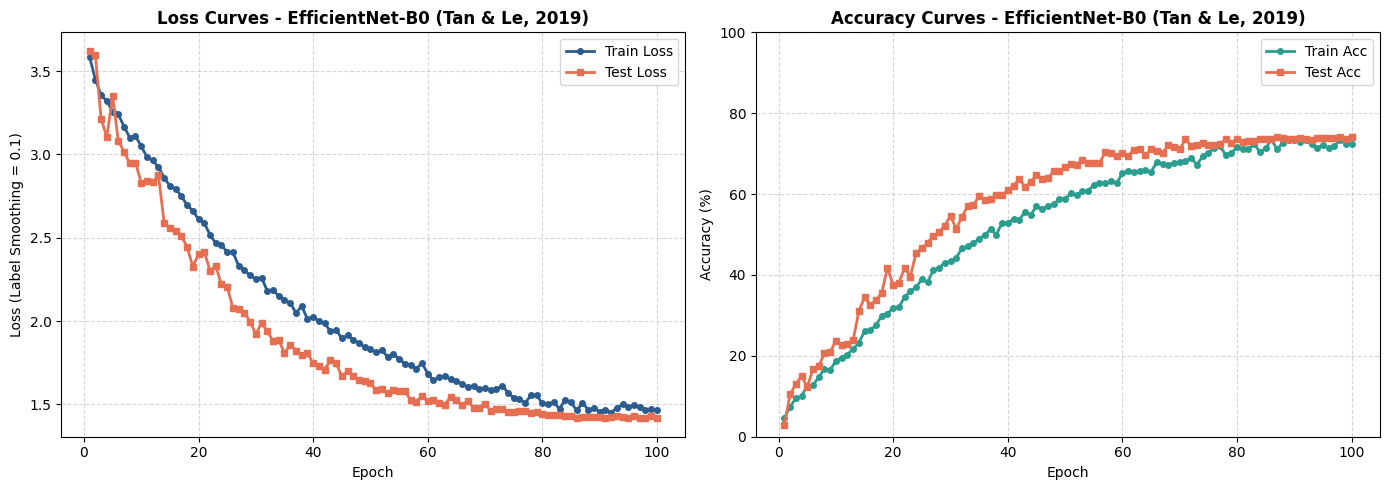

>> Đã nạp trọng số tốt nhất: Epoch 87 (Best Acc: 74.19%)

================ KẾT QUẢ ĐỐI SÁNH ================
1. Test Accuracy chuẩn (Không dùng TTA)     : 74.19%
2. Test Accuracy tối ưu với 4-View Multi-TTA : 75.28%
>> Mức tăng trưởng đạt được nhờ 4-View TTA   : +1.09%



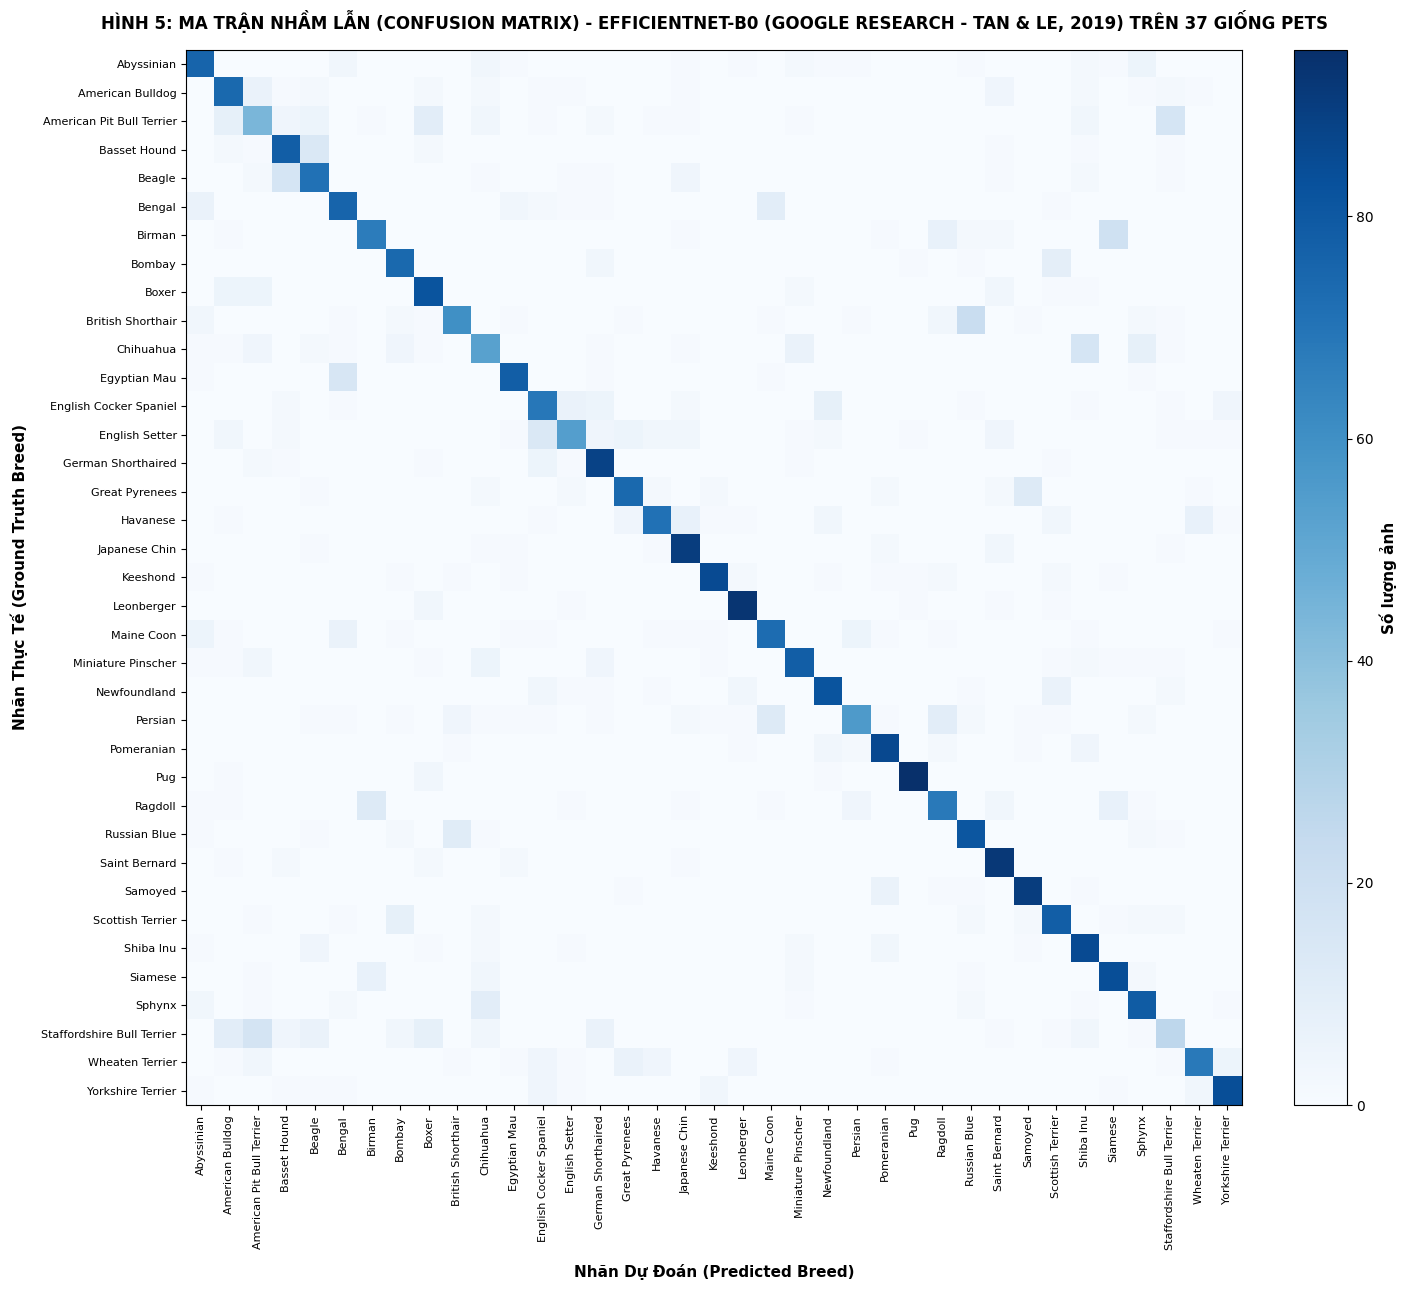

Đã lưu kết quả đối sánh tại: ./plots/foreground/efficientnet_metrics.json


In [7]:
import torch.nn.functional as F
os.makedirs(args.plots_dir, exist_ok=True)
epochs_range = range(1, len(train_losses) + 1)

# 1. Đường cong Loss & Accuracy (Thống nhất thang đo trực quan)
plt.figure(figsize=(14, 5))

# Subplot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, 'o-', label='Train Loss', color='#2b5c8f', lw=2, markersize=4)
plt.plot(epochs_range, test_losses, 's-', label='Test Loss', color='#e76f51', lw=2, markersize=4)
plt.title(f"Loss Curves - EfficientNet-B0 (Tan & Le, 2019)", fontweight="bold")
plt.xlabel('Epoch')
plt.ylabel('Loss (Label Smoothing = 0.1)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Subplot 2: Accuracy (Trục y cố định 0% đến 100%)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accs, 'o-', label='Train Acc', color='#2a9d8f', lw=2, markersize=4)
plt.plot(epochs_range, test_accs, 's-', label='Test Acc', color='#e76f51', lw=2, markersize=4)
plt.title(f"Accuracy Curves - EfficientNet-B0 (Tan & Le, 2019)", fontweight="bold")
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
curve_path = os.path.join(args.plots_dir, "efficientnet_curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()

# 2. Nạp lại trọng số của epoch tốt nhất (Best Acc) để đánh giá ma trận nhầm lẫn
if os.path.exists(best_ckpt):
    best_ckpt_data = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(best_ckpt_data["model_state_dict"])
    print(f">> Đã nạp trọng số tốt nhất: Epoch {best_ckpt_data['epoch']:02d} (Best Acc: {best_ckpt_data['best_acc']:.2f}%)")

model.eval()

# Đánh giá kiểm thử với 4-View Multi-Scale TTA
all_preds_raw, all_preds_tta, all_targets = [], [], []

with torch.no_grad():
    for inputs, targets, _ in testloader:
        inputs = inputs.to(device)
        targets = targets.numpy()

        # View 1: Ảnh gốc
        p1 = F.softmax(model(inputs), dim=1)
        preds_raw = p1.max(1)[1].cpu().numpy()

        # View 2: Lật ngang Horizontal Flip
        p2 = F.softmax(model(torch.flip(inputs, dims=[-1])), dim=1)

        # View 3: Cắt trọng tâm và phóng to 1.1x (Zoomed View)
        h, w = inputs.shape[2], inputs.shape[3]
        h_c, w_c = int(h * 0.9), int(w * 0.9)
        top, left = (h - h_c) // 2, (w - w_c) // 2
        crop = inputs[:, :, top:top+h_c, left:left+w_c]
        inputs_zoom = F.interpolate(crop, size=(h, w), mode="bilinear", align_corners=False)
        p3 = F.softmax(model(inputs_zoom), dim=1)

        # View 4: Phóng to kết hợp lật ngang
        p4 = F.softmax(model(torch.flip(inputs_zoom, dims=[-1])), dim=1)

        # Weighted Ensemble: 40% Gốc + 30% Flip + 15% Zoom + 15% Zoom-Flip
        probs_tta = (p1 * 0.4) + (p2 * 0.3) + (p3 * 0.15) + (p4 * 0.15)
        preds_tta = probs_tta.max(1)[1].cpu().numpy()

        all_preds_raw.extend(preds_raw)
        all_preds_tta.extend(preds_tta)
        all_targets.extend(targets)

acc_raw = 100.0 * np.mean(np.array(all_preds_raw) == np.array(all_targets))
acc_tta = 100.0 * np.mean(np.array(all_preds_tta) == np.array(all_targets))

print()
print("================ KẾT QUẢ ĐỐI SÁNH ================")
print(f"1. Test Accuracy chuẩn (Không dùng TTA)     : {acc_raw:.2f}%")
print(f"2. Test Accuracy tối ưu với 4-View Multi-TTA : {acc_tta:.2f}%")
print(f">> Mức tăng trưởng đạt được nhờ 4-View TTA   : +{acc_tta - acc_raw:.2f}%")
print("===================================================")
print()

cm = confusion_matrix(all_targets, all_preds_tta)
breed_names = [name.replace('_', ' ').title() for name in testset.class_names]

plt.figure(figsize=(15, 13))
im = plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title(f"HÌNH 5: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) - EFFICIENTNET-B0 (GOOGLE RESEARCH - TAN & LE, 2019) TRÊN 37 GIỐNG PETS", fontweight="bold", fontsize=12, pad=15)
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label('Số lượng ảnh', fontweight='bold', fontsize=11)

tick_marks = np.arange(len(breed_names))
plt.xticks(tick_marks, breed_names, rotation=90, fontsize=8)
plt.yticks(tick_marks, breed_names, fontsize=8)

plt.xlabel('Nhãn Dự Đoán (Predicted Breed)', fontweight='bold', fontsize=11, labelpad=10)
plt.ylabel('Nhãn Thực Tế (Ground Truth Breed)', fontweight='bold', fontsize=11, labelpad=10)
plt.tight_layout()
cm_path = os.path.join(args.plots_dir, "efficientnet_confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()

# 3. Xuất file tóm tắt chỉ số định lượng
metrics_summary = {
    "model_name": "EfficientNet-B0 (Tan & Le, 2019)",
    "total_params": total_params,
    "batch_size": args.batch_size,
    "epochs_trained": len(train_losses),
    "final_train_loss": round(train_losses[-1], 3) if train_losses else None,
    "final_train_acc": round(train_accs[-1], 2) if train_accs else None,
    "final_test_loss": round(test_losses[-1], 3) if test_losses else None,
    "final_test_acc": round(test_accs[-1], 2) if test_accs else None,
    "best_test_acc_raw": round(acc_raw, 2),
    "best_test_acc_tta": round(acc_tta, 2),
    "delta_tta_gain": round(acc_tta - acc_raw, 2)
}
metrics_file = os.path.join(args.plots_dir, "efficientnet_metrics.json")
with open(metrics_file, "w") as f:
    json.dump(metrics_summary, f, indent=2)
print(f"Đã lưu kết quả đối sánh tại: {metrics_file}")
